# **BASELINE MODELS NOTEBOOK**

(ACTUALIZAR A INDICE FINAL DEL NOTEBOOK)

1. Notebook Setup

2. Load Prepared Baseline Data

3. Modelling Strategy

4. AI Studio Benchmark

   4.1 Benchmark Objective

   4.2 Dataset Used

   4.3 AI Studio Configuration

   4.4 Candidate Models

   4.5 Evaluation Metric

   4.6 Benchmark Results

   4.7 Best AI Studio Model

   4.8 Benchmark Conclusions

5. Python Baseline Models

   5.1 Logistic Regression

   5.2 Decision Tree

   5.3 Random Forest

   5.4 Gradient Boosting / similar baseline

   5.5 Baseline Model Comparison

   5.6 Baseline Model Selection

   5.7 Export Baseline Results

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    roc_auc_score,
    roc_curve,
    PrecisionRecallDisplay,
    precision_recall_curve,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
import time
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)


## 1. Notebook Setup

This notebook establishes the modelling benchmark for the Home Credit Default Risk project.

The main objectives are:

- establish the AI Studio benchmark required by the assignment;
- evaluate baseline machine-learning models using the prepared baseline dataset;
- use ROC-AUC as the primary model-selection metric;
- maintain the train / validation / internal test split created during Data Preparation;
- compare models under the same experimental conditions;
- identify the strongest baseline model before advanced modelling.

No data cleaning, feature engineering, splitting or preprocessing decisions are learned again in this notebook. These steps were completed in `02_data_preparation.ipynb`.

The internal test set will remain untouched until the final baseline model has been selected using the validation set.

In [3]:
#Para tener cambios reproducibles
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [4]:
#Project paths
PROJECT_ROOT = Path("..")
DATA_DIR = (PROJECT_ROOT / "data")
PROCESSED_DATA_DIR = (DATA_DIR / "processed")
OUTPUT_DIR = (PROJECT_ROOT / "outputs" / "baseline_models")
MODEL_DIR = (PROJECT_ROOT / "models" / "baseline")
SPLITS_DIR = (PROCESSED_DATA_DIR / "splits")
AI_STUDIO_DIR = (PROCESSED_DATA_DIR / "ai_studio")
BASELINE_DATA_DIR = (PROCESSED_DATA_DIR / "baseline")
PREPROCESSING_DIR = (PROJECT_ROOT / "models" / "preprocessing")

In [5]:
#Crear los output directories y subcarpetas con los que trabajamos
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
AI_STUDIO_RESULTS_DIR = (OUTPUT_DIR / "ai_studio")
PYTHON_RESULTS_DIR = (OUTPUT_DIR / "python")
FIGURES_DIR = (OUTPUT_DIR / "figures")

for directory in [AI_STUDIO_RESULTS_DIR, PYTHON_RESULTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

In [6]:
#Definición de constantes
TARGET_COLUMN = "TARGET"
ID_COLUMN = "SK_ID_CURR"
PRIMARY_METRIC = "ROC-AUC"
SECONDARY_METRICS = ["PR-AUC", "Accuracy", "Precision",  "Recall", "F1"]
DEFAULT_THRESHOLD = 0.50 #Se optimizará en la parte de evaluación por el desbalanceo que tenemos en la variable target (0: 92%, 1: 8%)
BASELINE_SCALED_NAME = "Baseline Scaled"
BASELINE_UNSCALED_NAME = "Baseline Unscaled"

In [7]:
#Enviroment Verification
required_directories = {
    "Processed Data": PROCESSED_DATA_DIR,
    "Splits": SPLITS_DIR,
    "AI Studio": AI_STUDIO_DIR,
    "Baseline Data": BASELINE_DATA_DIR,
    "Preprocessing Models": PREPROCESSING_DIR
}

directory_verification = []
for name, path in required_directories.items():
    directory_verification.append({
        "Directory": name,
        "Path": str(path),
        "Exists": path.exists()
    })

directory_verification = pd.DataFrame(directory_verification)
directory_verification

,Directory,Path,Exists
0,Processed Data,../data/processed,True
1,Splits,../data/processed/splits,True
2,AI Studio,../data/processed/ai_studio,True
3,Baseline Data,../data/processed/baseline,True
4,Preprocessing Models,../models/preprocessing,True


In [8]:
#Comprobar existencia de archivos necesarios
required_files = {
    "Train IDs": SPLITS_DIR / "train_ids.csv",
    "Validation IDs": SPLITS_DIR / "validation_ids.csv",
    "Test IDs": SPLITS_DIR / "test_ids.csv",
    "y_train": SPLITS_DIR / "y_train.csv",
    "y_validation": SPLITS_DIR / "y_validation.csv",
    "y_test": SPLITS_DIR / "y_test.csv",
    "AI Studio Train": AI_STUDIO_DIR / "ai_studio_train.csv",
    "AI Studio Validation": AI_STUDIO_DIR / "ai_studio_validation.csv",
    "AI Studio Test": AI_STUDIO_DIR / "ai_studio_test.csv",
    "Baseline Scaled Feature Names": BASELINE_DATA_DIR / "scaled_feature_names.csv",
    "Baseline Unscaled Feature Names": BASELINE_DATA_DIR / "unscaled_feature_names.csv"
}

file_verification = []
for name, path in required_files.items():
    file_verification.append({
        "Artifact": name,
        "Path": str(path),
        "Exists": path.exists()
    })

file_verification = pd.DataFrame(file_verification)
file_verification

,Artifact,Path,Exists
0,Train IDs,../data/processed/splits/train_ids.csv,True
1,Validation IDs,../data/processed/splits/validation_ids.csv,True
2,Test IDs,../data/processed/splits/test_ids.csv,True
3,y_train,../data/processed/splits/y_train.csv,True
4,y_validation,../data/processed/splits/y_validation.csv,True
5,y_test,../data/processed/splits/y_test.csv,True
6,AI Studio Train,../data/processed/ai_studio/ai_studio_train.csv,True
7,AI Studio Validation,../data/processed/ai_studio/ai_studio_validati...,True
8,AI Studio Test,../data/processed/ai_studio/ai_studio_test.csv,True
9,Baseline Scaled Feature Names,../data/processed/baseline/scaled_feature_name...,True


## 2. Load Prepared Baseline Data

2.1 Load Target Splits

In [9]:
y_train_df = pd.read_csv(SPLITS_DIR / "y_train.csv")
y_validation_df = pd.read_csv(SPLITS_DIR / "y_validation.csv")
y_test_df = pd.read_csv(SPLITS_DIR / "y_test.csv")

In [10]:
#Scikit-learn trabaja con Series, por lo que hay que convertirlos
y_train = y_train_df[TARGET_COLUMN].copy()
y_validation = y_validation_df[TARGET_COLUMN].copy()
y_test = y_test_df[TARGET_COLUMN].copy()

print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)
print("y_test:", y_test.shape)

y_train: (215257,)
y_validation: (46127,)
y_test: (46127,)


2.2 Load Baseline Feature Matrices

In [11]:
#Cargar las matrices guardadas en data_preparation notebook
def load_saved_matrix(directory, base_filename):
    npz_path = directory / f"{base_filename}.npz"
    npy_path = directory / f"{base_filename}.npy"

    if npz_path.exists():
        return sparse.load_npz(npz_path)
    elif npy_path.exists():
        return np.load(npy_path)
    else:
        raise FileNotFoundError(f"No matrix found for {base_filename}")


In [12]:
#Cargar matrices scaladas del Baseline
X_train_baseline_scaled = load_saved_matrix(BASELINE_DATA_DIR, "X_train_scaled")
X_validation_baseline_scaled = load_saved_matrix(BASELINE_DATA_DIR, "X_validation_scaled")
X_test_baseline_scaled = load_saved_matrix(BASELINE_DATA_DIR, "X_test_scaled")

In [13]:
#Cargar matrices no escaladas del Baseline
X_train_baseline_unscaled = load_saved_matrix(BASELINE_DATA_DIR, "X_train_unscaled")
X_validation_baseline_unscaled = load_saved_matrix(BASELINE_DATA_DIR, "X_validation_unscaled")
X_test_baseline_unscaled = load_saved_matrix(BASELINE_DATA_DIR, "X_test_unscaled")

Cargamos tanto scaled como unscaled porque cada uno va a ser utilizado para distintos algoritmos.

Scaled

→ Logistic Regression

→ SVM

→ KNN

Unscaled

→ Decision Tree

→ Random Forest

→ Gradient Boosting

2.3 Load Feature Names

In [14]:
baseline_scaled_feature_names = pd.read_csv(BASELINE_DATA_DIR / "scaled_feature_names.csv")["Feature"].tolist()
baseline_unscaled_feature_names = pd.read_csv(BASELINE_DATA_DIR / "unscaled_feature_names.csv")["Feature"].tolist()

2.4 Verify Train / Validation / Test Alignment

In [15]:
assert (X_train_baseline_scaled.shape[0] == len(y_train))
assert (X_validation_baseline_scaled.shape[0] == len(y_validation))
assert (X_test_baseline_scaled.shape[0] == len(y_test))

In [16]:
assert (X_train_baseline_unscaled.shape[0] == len(y_train))
assert (X_validation_baseline_unscaled.shape[0] == len(y_validation))
assert (X_test_baseline_unscaled.shape[0] == len(y_test))

2.5 Verify Target Distribution

Necesitamos comprobar que con cada proceso de feature engineering que hacemos, se siga manteniendo el porcentaje de distribución desbalanceada de la variable TARGET

In [17]:
def summarize_target(y, split_name):
    return {
        "Split": split_name,
        "Rows": len(y),
        "TARGET_0_Count": (y == 0).sum(),
        "TARGET_1_Count": (y == 1).sum(),
        "TARGET_0_Rate": (y == 0).mean() * 100,
        "TARGET_1_Rate":(y == 1).mean() * 100
    }

In [18]:
target_split_summary = pd.DataFrame([
    summarize_target(y_train, "Train"),
    summarize_target(y_validation, "Validation"),
    summarize_target(y_test, "Test")
])

target_split_summary

,Split,Rows,TARGET_0_Count,TARGET_1_Count,TARGET_0_Rate,TARGET_1_Rate
0,Train,215257,197880,17377,91.927324,8.072676
1,Validation,46127,42403,3724,91.926637,8.073363
2,Test,46127,42403,3724,91.926637,8.073363


2.6 Verify Missing and Infinite Values

In [19]:
def matrix_contains_nan(matrix):
    if sparse.issparse(matrix):
        return np.isnan(matrix.data).any()
    return np.isnan(matrix).any()

def matrix_contains_infinite(matrix):
    if sparse.issparse(matrix):
        return np.isinf(matrix.data).any()
    return np.isinf(matrix).any()

In [20]:
baseline_loaded_matrices = {
    "Train Scaled": X_train_baseline_scaled,
    "Validation Scaled": X_validation_baseline_scaled,
    "Test Scaled": X_test_baseline_scaled,
    "Train Unscaled": X_train_baseline_unscaled,
    "Validation Unscaled": X_validation_baseline_unscaled,
    "Test Unscaled": X_test_baseline_unscaled
}

loaded_data_quality = []

for name, matrix in baseline_loaded_matrices.items():
    loaded_data_quality.append({
        "Dataset": name,
        "Contains NaN": matrix_contains_nan(matrix),
        "Contains Infinite":matrix_contains_infinite(matrix)
    })

loaded_data_quality = pd.DataFrame(loaded_data_quality)
loaded_data_quality

,Dataset,Contains NaN,Contains Infinite
0,Train Scaled,False,False
1,Validation Scaled,False,False
2,Test Scaled,False,False
3,Train Unscaled,False,False
4,Validation Unscaled,False,False
5,Test Unscaled,False,False


2.7 Final Data Loading Summary

In [21]:
baseline_data_summary = pd.DataFrame({
    "Representation": [
        "Scaled",
        "Unscaled"
    ],
    "Train Rows": [
        X_train_baseline_scaled.shape[0],
        X_train_baseline_unscaled.shape[0]
    ],
    "Validation Rows": [
        X_validation_baseline_scaled.shape[0],
        X_validation_baseline_unscaled.shape[0]
    ],
    "Test Rows": [
        X_test_baseline_scaled.shape[0],
        X_test_baseline_unscaled.shape[0]
    ],
    "Features": [
        X_train_baseline_scaled.shape[1],
        X_train_baseline_unscaled.shape[1]
    ],
    "NaN Free": [
        not matrix_contains_nan(
            X_train_baseline_scaled
        ),
        not matrix_contains_nan(
            X_train_baseline_unscaled
        )
    ],
    "Infinite Free": [
        not matrix_contains_infinite(
            X_train_baseline_scaled
        ),
        not matrix_contains_infinite(
            X_train_baseline_unscaled
        )
    ]
})

baseline_data_summary

,Representation,Train Rows,Validation Rows,Test Rows,Features,NaN Free,Infinite Free
0,Scaled,215257,46127,46127,242,True,True
1,Unscaled,215257,46127,46127,242,True,True


In [22]:
#Guardamos los resultados
baseline_data_summary.to_csv(OUTPUT_DIR / "baseline_data_loading_summary.csv", index=False)
target_split_summary.to_csv(OUTPUT_DIR / "target_split_summary.csv", index=False)
loaded_data_quality.to_csv(OUTPUT_DIR / "loaded_data_quality.csv", index=False)

## 3. Modelling Strategy

3.1 Experimental Objective

The objective of this modelling stage is to establish a reproducible benchmark and compare a set of baseline classification models under consistent experimental conditions.

The modelling process follows two stages:

1. establish an AI Studio benchmark using the prepared baseline dataset;
2. train baseline Python models using the same underlying data split and evaluate whether Python-based modelling can match or improve the benchmark.

ROC-AUC is used as the primary model-selection metric because the target variable is highly imbalanced and the project focuses on the model's ability to discriminate between applicants with and without payment difficulties.

3.2 Benchmarking Sequence

Orden de experimentación fijado

1. AI Studio benchmark
2. Python baseline models
3. Baseline comparison
4. Select strongest baseline model
5. Internal test evaluation

Experimental sequence

AI Studio candidate models
        
        ↓

Best AI Studio validation ROC-AUC
        
        ↓

AI Studio benchmark
        
        ↓

Python baseline models
        
        ↓

Validation comparison
        
        ↓

Best baseline model selected
        
        ↓

Internal test evaluation

3.3 Dataset Usage

Para este notebook utilizamos Dataset -> Baseline solo.

Nuestra comprobación principal será: AI Studio Baseline vs Python Baseline.

1. Utilizamos Train para el fit models, contiene el 70% del dataset original. En Python utilizamos X_train_baseline_scaled o X_train_baseline_unscaled según el alñgoritmo que estemos desarrollando y entrenando; y y_train.

2. Utilizamos Validation para model comparison, hyperparameter decisions and model selection. En Python utilizamos X_validation_baseline_scaled, X_validation_baseline_unscaled y y_validation. Sobre esta particion compararemos ROC-AUC, PR-AUC, Precision, Recall, F1, Accuracy.

3. Utilizamos Test para final evaluation only.

3.4 Candidate Baseline Models

Los modelos que inicialmente vamos a comparar con el baseline son: Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting; ya que representan familias distintas de modelos.

**Logistic Regression**
- Family: Linear Model
- Input: Scaled baseline data
- Ventajas: Interpretable, fast, strong traditional baseline and good reference for tabular binary classification
- Usará X_train_baseline_scaled

**Decision Tree**
- Family: Single Tree
- Input: Unscaled baseline data
- Ventajas: Captures nonlinear relationships, easy to understand and does not require scaling
- Usará X_train_baseline_unscaled

**Random Forest**
- Family: Bagging ensemble
- Input: Unscaled baseline data
- Ventajas: Permite comprobar cuanto mejora un ensemble respecto a un único árbol
- Usará X_train_baseline_unscaled

**HistGradientBoosting**
- Family: Boosting
- Input: Unscaled baseline data

In [23]:
baseline_model_strategy = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "Model Family": [
        "Linear",
        "Single Tree",
        "Bagging Ensemble",
        "Boosting Ensemble"
    ],
    "Input Representation": [
        "Scaled",
        "Unscaled",
        "Unscaled",
        "Unscaled"
    ],
    "Primary Role": [
        "Simple linear baseline",
        "Simple nonlinear baseline",
        "Ensemble baseline",
        "Boosting baseline"
    ]
})

baseline_model_strategy

,Model,Model Family,Input Representation,Primary Role
0,Logistic Regression,Linear,Scaled,Simple linear baseline
1,Decision Tree,Single Tree,Unscaled,Simple nonlinear baseline
2,Random Forest,Bagging Ensemble,Unscaled,Ensemble baseline
3,HistGradientBoosting,Boosting Ensemble,Unscaled,Boosting baseline


In [24]:
baseline_model_strategy.to_csv(OUTPUT_DIR / "baseline_model_strategy.csv", index=False)

3.5 Evaluation Metrics

In [25]:
#La métrica primaria es:
PRIMARY_METRIC = "ROC-AUC"

ROC-AUC nos permite medir la capacidad de ranking. Conceptualmente:

- 0.50 -> random discrimination
- closer to 1 -> stronger discrimination

Para el proyecto, higher ROC-AUC -> better ability to rank risky applicants above non-risky applicants.

También calculamos PR-AUC mediante average_precision_score, especialmente útil esta estádistica puesto que TARGET = 1 es una clase minoritaria.

Con Threshold = 0.50 podemos calcular posteriormente Accuracy, Precision, Recall y F1.

In [26]:
DEFAULT_THRESHOLD = 0.50

3.6 Validation and Test Usage

- TRAIN -> Learn model parameters
- VALIDATION -> Compare models (Compare ROC-AUC, compare model families, select hyperparameters, select final baseline candidate)
- TEST -> Final evaluation

3.7 Model Selection Rule

Regla para elegir el modelo ganador:

The model with the highest validation ROC-AUC will be selected as primary baseline candidate.

Si dos modelos presentan practicamente ROC-AUC idénticos, se utilizarán otras métricas como: PR-AUC, stability, complexity, training time, interpretability. Por ejemplo:

    Model A ROC-AUC = 0.7421
    Model B ROC-AUC = 0.7422

La regla será:

Primary:

    Validation ROC-AUC

Supporting:

    PR-AUC

    Recall

    F1

    Model complexity

    Training time

Es también importante dejar claro que consideramos como mejora respecto a los resultados de AI Studio.

Tras que veamos los resultados de los modelos de AI Studio, tendremos ai_studio_benchmark_auc y en python al igual por cada modelo tendremos python_auc, lo que nos lleva a poder definir que si: (Python ROC-AUC - AI Studio ROC-AUC) > 0, hay una diferencia positiva por parte del modelo de python respecto al modelo de ai studio y podremos decir que este gue superado. De igual modo si la diferencia es = 0, son comparables y si la diferencia < 0, el modelo de python no superó al benchmark de ai studio.

3.8 Preparar estructura de resultados

In [27]:
baseline_results_columns = [
    "Model",
    "Dataset",
    "Representation",
    "ROC-AUC",
    "PR-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Training Time Seconds"
]
baseline_results = pd.DataFrame(columns=baseline_results_columns)
baseline_results #Lo tenemos vacio porque no tenemos modelos todavía, lo iremos añadiendo.

,Model,Dataset,Representation,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Training Time Seconds


In [28]:
#Función común de evaluación
def evaluate_binary_classifier(
    model_name,
    y_true,
    probabilities,
    threshold=DEFAULT_THRESHOLD,
    dataset_name="Validation",
    representation=None,
    training_time=None
):
    predictions = (probabilities >= threshold).astype(int)

    results = {
        "Model": model_name,
        "Dataset": dataset_name,
        "Representation": representation,
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall":recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Training Time Seconds": training_time
    }
    return results

3.10 Strategy Summary

In [29]:
modelling_strategy_summary = pd.DataFrame({
    "Component": [
        "Benchmark",
        "Primary Metric",
        "Supporting Metrics",
        "Training Data",
        "Model Selection Data",
        "Final Evaluation Data",
        "Default Classification Threshold",
        "Python Baseline Models",
        "Advanced Data Used"
    ],
    "Decision": [
        "AI Studio",
        "Validation ROC-AUC",
        "PR-AUC, Accuracy, Precision, Recall, F1",
        "Internal Train",
        "Internal Validation",
        "Internal Test",
        DEFAULT_THRESHOLD,
        ("Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting"),
        "No"
    ]
})
modelling_strategy_summary

,Component,Decision
0,Benchmark,AI Studio
1,Primary Metric,Validation ROC-AUC
2,Supporting Metrics,"PR-AUC, Accuracy, Precision, Recall, F1"
3,Training Data,Internal Train
4,Model Selection Data,Internal Validation
5,Final Evaluation Data,Internal Test
6,Default Classification Threshold,0.5
7,Python Baseline Models,"Logistic Regression, Decision Tree, Random For..."
8,Advanced Data Used,No


In [30]:
modelling_strategy_summary.to_csv(OUTPUT_DIR / "modelling_strategy_summary.csv", index=False)

## 4. AI Studio Benchmark

The principal rule will be:

- AI Studio Train -> Train the models
- AI Studio Validation -> Compare and select the best models
- AI Studio Test -> Evaluate one time only the model selected

4.1 Benchmark Objective

The objective of this section is to establish a reproducible external benchmark using Altair AI Studio before developing the Python baseline models.

AI Studio is first used as an automated modelling environment to screen several classification algorithms. However, the internal validation procedure generated automatically by Auto Model is not used as the final project benchmark because it does not correspond to the fixed train, validation and test partitions established during Data Preparation.

Therefore, the AI Studio workflow is evaluated in two distinct stages:

1. **Auto Model screening**, used to identify promising candidate algorithms.

2. **Fixed-split evaluation**, where selected candidates are retrained using the predefined training partition and evaluated on the predefined validation partition.

The primary model-selection metric is **ROC-AUC**, consistent with the original Home Credit competition metric and the modelling strategy established previously.

The internal test set is reserved for the final evaluation of the model selected using validation performance.

4.2 Benchmark Dataset

We use the next files generated on the notebook 02_data_preparation.ipynb to make the benchmark we use later to improve in python.

data/processed/ai_studio/

    ai_studio_train.csv
    ai_studio_validation.csv
    ai_studio_test.csv

In [31]:
#Comprobar que existen los archivos anteriormente creados
ai_studio_train_path = (AI_STUDIO_DIR / "ai_studio_train.csv")
ai_studio_validation_path = (AI_STUDIO_DIR / "ai_studio_validation.csv")
ai_studio_test_path = (AI_STUDIO_DIR / "ai_studio_test.csv")

In [32]:
ai_studio_files = pd.DataFrame({
    "Split": [
        "Train",
        "Validation",
        "Test"
    ],
    "File": [
        str(ai_studio_train_path),
        str(ai_studio_validation_path),
        str(ai_studio_test_path)
    ],
    "Exists": [
        ai_studio_train_path.exists(),
        ai_studio_validation_path.exists(),
        ai_studio_test_path.exists()
    ]
})
ai_studio_files

,Split,File,Exists
0,Train,../data/processed/ai_studio/ai_studio_train.csv,True
1,Validation,../data/processed/ai_studio/ai_studio_validati...,True
2,Test,../data/processed/ai_studio/ai_studio_test.csv,True


![AI Studio training dataset overview](../outputs/baseline_models/ai_studio/ai_studio_01_train_dataset_overview.png)
![AI Studio target distribution](../outputs/baseline_models/ai_studio/ai_studio_02_target_distribution.png)

4.3 Auto Model Configuration

The initial AI Studio experiment was performed using Auto Model with `ai_studio_train.csv`.

Because `TARGET` was imported as a numerical 0/1 variable, the Auto Model target preparation stage converted it into a binary classification problem.

The following target configuration was used:

- Number of classes: 2

- Classification split: 0.5

- Class of highest interest: `range2`

- `range1` represents `TARGET = 0`

- `range2` represents `TARGET = 1`

No custom cost or benefit matrix was introduced at this stage because the objective was to establish a neutral modelling benchmark before later business-threshold analysis.

AI Studio identified 135 available predictors and automatically retained 100 predictors during its input-quality screening.

The remaining 35 predictors were automatically excluded by Auto Model according to its internal quality diagnostics, including factors such as stability, missingness and other input-quality characteristics.

This filtering was retained for the AI Studio benchmark because the objective of this stage was to evaluate the modelling workflow generated automatically by AI Studio rather than manually reproduce the feature-selection strategy used later in Python.

![AI Studio automatic input screening](../outputs/baseline_models/ai_studio/ai_studio_03_select_features.png)

*Figure: Auto Model input screening. AI Studio retained 100 of the 135 available predictors.*

In [33]:
ai_studio_input_summary = pd.DataFrame({
    "Measure": [
        "Available Predictors",
        "Auto Model Selected Predictors",
        "Auto Model Excluded Predictors"
    ],
    "Value": [135, 100, 35]
})
ai_studio_input_summary

,Measure,Value
0,Available Predictors,135
1,Auto Model Selected Predictors,100
2,Auto Model Excluded Predictors,35


Five classification algorithms were selected for the initial Auto Model screening:

- Naive Bayes
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosted Trees

These algorithms provide a heterogeneous comparison including probabilistic, linear, single-tree, bagging and boosting approaches.

Automatic optimisation options provided by AI Studio were retained where applicable during this initial screening stage.

![AI Studio candidate model configuration](../outputs/baseline_models/ai_studio/ai_studio_04_select_models.png)

4.4 Auto Model Candidate Screening

Auto Model evaluated 142 model configurations across the five selected algorithm families.

The initial comparison reported similar classification error values across several algorithms. However, because the dataset is strongly imbalanced, classification error and accuracy alone provide limited information about the ability to discriminate between low-risk and high-risk applicants.

For this reason, candidate models were ranked primarily using ROC-AUC.

In [34]:
ai_studio_screening_results = pd.DataFrame([
    {
        "Model": "Naive Bayes",
        "Accuracy": 0.919,
        "Classification Error": 0.081,
        "ROC-AUC": 0.515,
        "ROC-AUC Std": 0.003
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.919,
        "Classification Error": 0.081,
        "ROC-AUC": 0.747,
        "ROC-AUC Std": 0.006
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.919,
        "Classification Error": 0.081,
        "ROC-AUC": 0.500,
        "ROC-AUC Std": 0.000
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.920,
        "Classification Error": 0.080,
        "ROC-AUC": 0.573,
        "ROC-AUC Std": 0.010
    },
    {
        "Model": "Gradient Boosted Trees",
        "Accuracy": 0.920,
        "Classification Error": 0.080,
        "ROC-AUC": 0.714,
        "ROC-AUC Std": 0.016
    }
])

In [35]:
ai_studio_screening_results = ai_studio_screening_results.sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
ai_studio_screening_results["Screening Rank"] = np.arange(1, len(ai_studio_screening_results) + 1)
ai_studio_screening_results

,Model,Accuracy,Classification Error,ROC-AUC,ROC-AUC Std,Screening Rank
0,Logistic Regression,0.919,0.081,0.747,0.006,1
1,Gradient Boosted Trees,0.920,0.080,0.714,0.016,2
2,Random Forest,0.920,0.080,0.573,0.010,3
3,Naive Bayes,0.919,0.081,0.515,0.003,4
4,Decision Tree,0.919,0.081,0.500,0.000,5


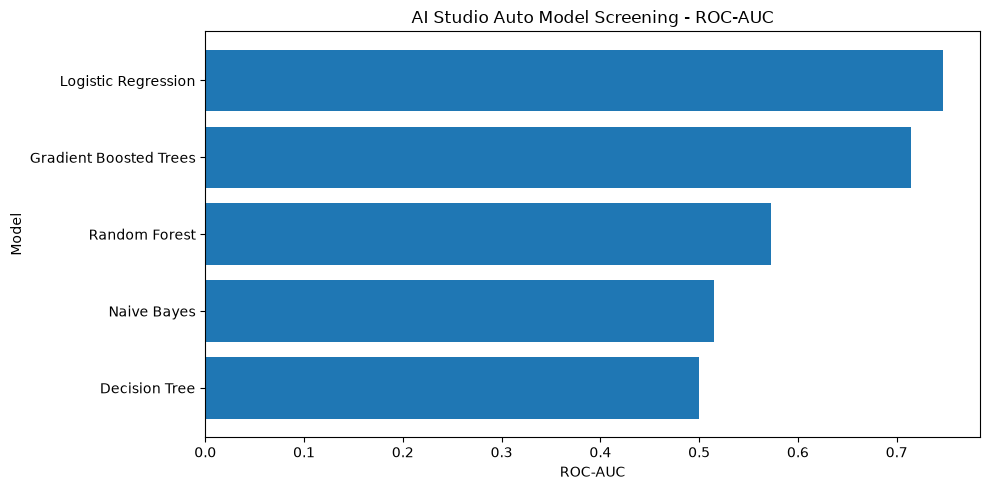

In [36]:
#Comparación Visual
plt.figure(figsize=(10, 5))

plt.barh(
    ai_studio_screening_results["Model"],
    ai_studio_screening_results["ROC-AUC"]
)

plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.title("AI Studio Auto Model Screening - ROC-AUC")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

The Auto Model screening identified Logistic Regression as the strongest initial candidate with an internal ROC-AUC of 0.747, followed by Gradient Boosted Trees with 0.714.

Random Forest achieved a substantially lower ROC-AUC of 0.573, while Naive Bayes and Decision Tree were close to random discrimination.

An important observation was that several models achieved approximately 92% accuracy despite having very different ROC-AUC values.

For example, Logistic Regression achieved an internal ROC-AUC of 0.747, whereas Decision Tree achieved approximately 0.500, despite both reporting approximately 91.9% accuracy.

This demonstrates why accuracy is potentially misleading for this highly imbalanced credit-risk problem and supports the decision to use ROC-AUC as the primary selection metric.

![AI Studio Auto Model overview](../outputs/baseline_models/ai_studio/ai_studio_05_auto_model_overview.png)

![AI Studio Auto Model ROC comparison](../outputs/baseline_models/ai_studio/ai_studio_06_roc_comparison.png)

#### Naive Bayes

![Naive Bayes screening performance](../outputs/baseline_models/ai_studio/ai_studio_screening_naive_bayes.png)

#### Logistic Regression

![Logistic Regression screening performance](../outputs/baseline_models/ai_studio/ai_studio_screening_logistic_regression.png)

#### Decision Tree

![Decision Tree screening performance](../outputs/baseline_models/ai_studio/ai_studio_screening_decision_tree.png)

#### Random Forest

![Random Forest screening performance](../outputs/baseline_models/ai_studio/ai_studio_screening_random_forest.png)

#### Gradient Boosted Trees

![Gradient Boosted Trees screening performance](../outputs/baseline_models/ai_studio/ai_studio_screening_gradient_boosting.png)

4.5 Fixed Validation Experimental Design

The Auto Model screening results were not adopted directly as the formal benchmark.

Inspection of the generated Auto Model process showed that AI Studio created its own internal validation partition from `ai_studio_train.csv`.

The automatically generated `Split Data` operator used:

- Training proportion: 0.60

- Validation proportion: 0.40

- Local random seed: 1992

Therefore, the internal Auto Model AUC values were obtained using a different validation population from the fixed project validation dataset.

Using these internal values directly against Python models evaluated on the predefined project validation set would create an unfair comparison.

To ensure experimental consistency, copies of the generated AI Studio processes were created and modified so that:

- `ai_studio_train.csv` was used in full for model training.
- `ai_studio_validation.csv` was used in full for model selection.
- No additional train/validation split was created inside AI Studio.
- The preprocessing learned from training data was subsequently applied to the fixed validation data.
- The same fixed validation population was therefore used for the AI Studio and Python experiments.

Because the externally imported validation file stored `TARGET` as an integer label with values 0 and 1, while Auto Model internally represented the classification target using `range1` and `range2`, the validation target was discretised to maintain compatibility with the generated AI Studio model.

The transformation was applied only to `TARGET`:

- `TARGET = 0` → `range1`
- `TARGET = 1` → `range2`

No predictor variables were modified by this operation.

The automatically generated AI Studio process also contained components for:

- scoring datasets,
- prediction explanations,
- model simulation,
- production-model generation,
- runtime aggregation,
- repeated hold-out evaluation.

These components were not required for the fixed-validation benchmark and depended on the original Auto Model validation architecture.

They were therefore removed from the benchmark copies.

The resulting benchmark workflow was reduced to the components required for a controlled experiment:

Training data
→ training preprocessing
→ model fitting
→ validation preprocessing
→ model application
→ binary classification performance.

![AI Studio fixed-validation pipeline](../outputs/baseline_models/ai_studio/ai_studio_lr_fixed_validation_pipeline.png)

![Fixed-validation performance configuration](../outputs/baseline_models/ai_studio/ai_studio_lr_fixed_validation_performance_config.png)

4.6 AI Studio Model Configurations

Gradient Boosting Model AI-Studio

In [37]:
ai_studio_gbt_config = pd.DataFrame({
    "Parameter": [
        "Number of Trees",
        "Maximum Depth",
        "Minimum Rows",
        "Minimum Split Improvement",
        "Number of Bins",
        "Learning Rate",
        "Sample Rate",
        "Distribution",
        "Reproducible",
        "Local Random Seed"
    ],
    "Value": [
        20,
        10,
        10.0,
        0.0,
        20,
        0.1,
        1.0,
        "AUTO",
        True,
        1992
    ]
})

ai_studio_gbt_config

,Parameter,Value
0,Number of Trees,20
1,Maximum Depth,10
2,Minimum Rows,10.0
3,Minimum Split Improvement,0.0
4,Number of Bins,20
5,Learning Rate,0.1
6,Sample Rate,1.0
7,Distribution,AUTO
8,Reproducible,True
9,Local Random Seed,1992


The Gradient Boosted Trees configuration generated by AI Studio was retained without manual hyperparameter tuning.

Random Forest Model AI-Studio

In [38]:
ai_studio_rf_config = pd.DataFrame({
    "Parameter": [
        "Number of Trees",
        "Criterion",
        "Maximum Depth",
        "Guess Subset Ratio",
        "Voting Strategy",
        "Local Random Seed"
    ],
    "Value": [
        100,
        "gain ratio",
        10,
        True,
        "confidence vote",
        1992
    ]
})

ai_studio_rf_config

,Parameter,Value
0,Number of Trees,100
1,Criterion,gain ratio
2,Maximum Depth,10
3,Guess Subset Ratio,True
4,Voting Strategy,confidence vote
5,Local Random Seed,1992


During reproducibility verification, the Random Forest process was identified as having local random seed control disabled in the initially generated workflow.

To ensure reproducibility across repeated executions, `use local random seed` was enabled and fixed to 1992 in both the validation and test Random Forest processes.

The model was subsequently rerun and only the results obtained after fixing the seed were retained for the final analysis.

Logistic Regression Model AI-Studio

In [39]:
ai_studio_lr_config = pd.DataFrame({
    "Parameter": [
        "Solver",
        "Reproducible",
        "Regularization",
        "Early Stopping",
        "Stopping Tolerance",
        "Standardize",
        "Add Intercept",
        "Remove Collinear Columns",
        "Missing Value Handling",
        "Local Random Seed"
    ],
    "Value": [
        "AUTO",
        True,
        False,
        True,
        0.001,
        True,
        True,
        True,
        "MeanImputation",
        1992
    ]
})

ai_studio_lr_config

,Parameter,Value
0,Solver,AUTO
1,Reproducible,True
2,Regularization,False
3,Early Stopping,True
4,Stopping Tolerance,0.001
5,Standardize,True
6,Add Intercept,True
7,Remove Collinear Columns,True
8,Missing Value Handling,MeanImputation
9,Local Random Seed,1992


4.7 Fixed Validation Results

#### Logistic Regression

Logistic Regression achieved a fixed-validation ROC-AUC of **0.713**.

![Logistic Regression fixed-validation ROC-AUC](../outputs/baseline_models/ai_studio/ai_studio_lr_fixed_validation_auc.png)
![Logistic Regression fixed-validation confusion matrix](../outputs/baseline_models/ai_studio/ai_studio_lr_fixed_validation_confusion_matrix.png)

Although Logistic Regression produced useful ranking performance, its default classification threshold resulted in no positive predictions in the validation set. This illustrates the distinction between threshold-independent ranking performance and threshold-dependent classification decisions.

#### Gradient Boosted Trees

Gradient Boosted Trees achieved the strongest fixed-validation discrimination, with a ROC-AUC of **0.724**.

![Gradient Boosted Trees fixed-validation ROC-AUC](../outputs/baseline_models/ai_studio/ai_studio_gbt_fixed_validation_auc.png)
![Gradient Boosted Trees fixed-validation confusion matrix](../outputs/baseline_models/ai_studio/ai_studio_gbt_fixed_validation_confusion_matrix.png)

Gradient Boosted Trees produced the strongest ranking performance among the evaluated AI Studio candidates. However, the default decision threshold remained highly conservative, producing very few positive classifications despite the substantially stronger ROC-AUC.

#### Random Forest

Random Forest was rerun after enabling a fixed local random seed of 1992 to ensure reproducible evaluation, with a ROC-AUC of **0.570**

![Random Forest fixed-validation ROC-AUC](../outputs/baseline_models/ai_studio/ai_studio_rf_fixed_validation_auc.png)
![Random Forest fixed-validation confusion matrix](../outputs/baseline_models/ai_studio/ai_studio_rf_fixed_validation_confusion_matrix.png)

In [40]:
ai_studio_validation_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": 0.713
    },
    {
        "Model": "Gradient Boosted Trees",
        "ROC-AUC": 0.724
    },
    {
        "Model": "Random Forest",
        "ROC-AUC": 0.570
    }
])

In [41]:
ai_studio_validation_results = (
    ai_studio_validation_results
    .sort_values(
        "ROC-AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

ai_studio_validation_results["Validation Rank"] = (
    np.arange(
        1,
        len(ai_studio_validation_results) + 1
    )
)

ai_studio_validation_results

,Model,ROC-AUC,Validation Rank
0,Gradient Boosted Trees,0.724,1
1,Logistic Regression,0.713,2
2,Random Forest,0.570,3


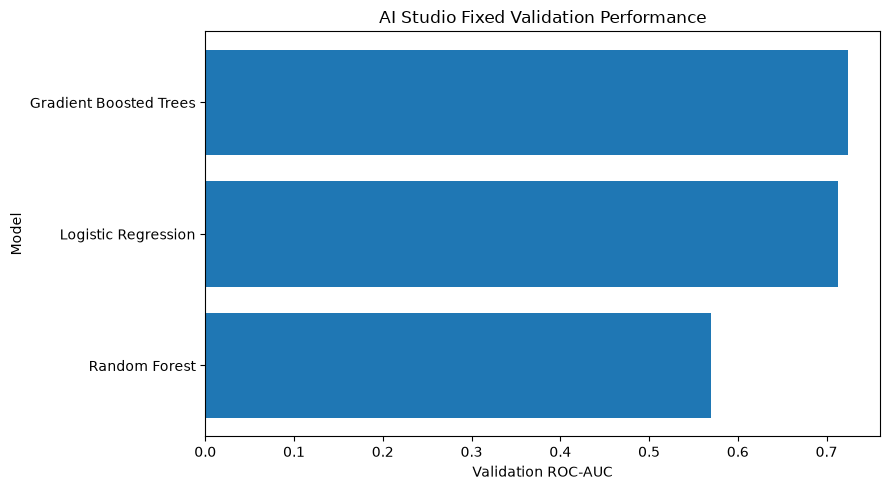

In [42]:
plt.figure(figsize=(9, 5))

plt.barh(
    ai_studio_validation_results["Model"],
    ai_studio_validation_results["ROC-AUC"]
)

plt.xlabel("Validation ROC-AUC")
plt.ylabel("Model")
plt.title("AI Studio Fixed Validation Performance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [43]:
ai_studio_gbt_validation_confusion = pd.DataFrame(
    [
        [42402, 1],
        [3720, 4]
    ],
    index=[
        "Actual TARGET 0",
        "Actual TARGET 1"
    ],
    columns=[
        "Predicted TARGET 0",
        "Predicted TARGET 1"
    ]
)

ai_studio_gbt_validation_confusion

,Predicted TARGET 0,Predicted TARGET 1
Actual TARGET 0,42402,1
Actual TARGET 1,3720,4


Despite producing the strongest validation ROC-AUC, Gradient Boosted Trees predicted very few applicants as the positive class at the default classification threshold.

This produced high overall accuracy but extremely low recall for `TARGET = 1`.

This behaviour does not contradict the ROC-AUC result.

ROC-AUC evaluates the ranking of predicted risk scores across all possible classification thresholds, whereas the confusion matrix reflects performance at one specific decision threshold.

Threshold optimisation is therefore deliberately deferred to the later Evaluation stage rather than being used during benchmark model selection.

4.8 AI Studio Benchmark Selection

In [44]:
best_ai_studio_validation_result = ai_studio_validation_results.iloc[0]
AI_STUDIO_BENCHMARK_MODEL = best_ai_studio_validation_result["Model"]
AI_STUDIO_BENCHMARK_VALIDATION_AUC = float(best_ai_studio_validation_result["ROC-AUC"])

In [45]:
print("AI Studio Benchmark Model:", AI_STUDIO_BENCHMARK_MODEL)
print("Validation ROC-AUC:", round(AI_STUDIO_BENCHMARK_VALIDATION_AUC, 3))

AI Studio Benchmark Model: Gradient Boosted Trees
Validation ROC-AUC: 0.724


The final AI Studio benchmark model was selected exclusively using fixed-validation ROC-AUC.

Gradient Boosted Trees achieved the strongest observed validation discrimination, with a ROC-AUC of 0.724.

This value is therefore adopted as the formal external benchmark that the subsequent Python modelling experiments will attempt to match or improve.

4.9 Internal Test Evaluation

In [46]:
AI_STUDIO_BENCHMARK_TEST_AUC = 0.726
ai_studio_benchmark_performance = pd.DataFrame({
    "Dataset": [
        "Validation",
        "Internal Test"
    ],
    "ROC-AUC": [
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        AI_STUDIO_BENCHMARK_TEST_AUC
    ]
})

ai_studio_benchmark_performance

,Dataset,ROC-AUC
0,Validation,0.724
1,Internal Test,0.726


![Gradient Boosted Trees internal-test ROC-AUC](../outputs/baseline_models/ai_studio/ai_studio_gbt_fixed_test_auc.png)
![Gradient Boosted Trees internal-test confusion matrix](../outputs/baseline_models/ai_studio/ai_studio_gbt_fixed_test_confusion_matrix.png)

4.10 Generalisation Assessment

In [47]:
ai_studio_generalisation_difference = AI_STUDIO_BENCHMARK_TEST_AUC - AI_STUDIO_BENCHMARK_VALIDATION_AUC
print("Validation ROC-AUC:", round(AI_STUDIO_BENCHMARK_VALIDATION_AUC, 3))
print("Test ROC-AUC:", round(AI_STUDIO_BENCHMARK_TEST_AUC, 3))
print("Test - Validation ROC-AUC:", round(ai_studio_generalisation_difference, 3))

Validation ROC-AUC: 0.724
Test ROC-AUC: 0.726
Test - Validation ROC-AUC: 0.002


The selected Gradient Boosted Trees benchmark achieved:

- Validation ROC-AUC: 0.724
- Internal Test ROC-AUC: 0.726

The absolute difference between validation and test discrimination was approximately 0.002.

The very small difference indicates that the discrimination observed during model selection was maintained on the independent internal test partition.

No material degradation in ROC-AUC was observed between validation and test.

4.11 Reproducibility Controls

Reproducibility was explicitly reviewed before closing the AI Studio benchmark.

The saved Gradient Boosted Trees process used:

- reproducible execution enabled,

- local random seed enabled,

- random seed = 1992.

Logistic Regression was also configured using the fixed random seed of 1992 within the generated classification workflow.

During inspection of the Random Forest process, local random-seed control was initially found to be disabled.

To avoid stochastic variation across repeated executions, the Random Forest validation and test processes were updated to use:

- local random seed enabled,

- random seed = 1992.

Both Random Forest experiments were rerun after this change, and only the reproducible rerun results were retained.

The complete AI Studio processes were saved in the project repository so that another team member can rerun the same workflows using the same data, model parameters and random seeds.

4.12 Export AI Studio Results

In [48]:
ai_studio_screening_results.to_csv(AI_STUDIO_RESULTS_DIR / "ai_studio_screening_results.csv", index=False)
ai_studio_validation_results.to_csv(AI_STUDIO_RESULTS_DIR / "ai_studio_fixed_validation_results.csv", index=False)

In [49]:
ai_studio_benchmark_summary = pd.DataFrame({
    "Measure": [
        "Benchmark Model",
        "Validation ROC-AUC",
        "Internal Test ROC-AUC",
        "Test - Validation Difference",
        "Positive Class",
        "Primary Metric",
        "Random Seed"
    ],
    "Value": [
        AI_STUDIO_BENCHMARK_MODEL,
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        AI_STUDIO_BENCHMARK_TEST_AUC,
        ai_studio_generalisation_difference,
        "TARGET = 1",
        "ROC-AUC",
        1992
    ]
})

ai_studio_benchmark_summary

,Measure,Value
0,Benchmark Model,Gradient Boosted Trees
1,Validation ROC-AUC,0.724
2,Internal Test ROC-AUC,0.726
3,Test - Validation Difference,0.002
4,Positive Class,TARGET = 1
5,Primary Metric,ROC-AUC
6,Random Seed,1992


In [50]:
ai_studio_benchmark_summary.to_csv(AI_STUDIO_RESULTS_DIR / "ai_studio_benchmark_summary.csv", index=False)

In [51]:
AI_STUDIO_BENCHMARK = {
    "model":AI_STUDIO_BENCHMARK_MODEL,
    "validation_roc_auc": AI_STUDIO_BENCHMARK_VALIDATION_AUC,
    "test_roc_auc": AI_STUDIO_BENCHMARK_TEST_AUC,
    "primary_metric": "ROC-AUC",
    "positive_class": 1,
    "random_seed": 1992
}
AI_STUDIO_BENCHMARK

{'model': 'Gradient Boosted Trees',
 'validation_roc_auc': 0.724,
 'test_roc_auc': 0.726,
 'primary_metric': 'ROC-AUC',
 'positive_class': 1,
 'random_seed': 1992}

The AI Studio benchmark was developed in two stages.

First, Auto Model was used to screen five different classification algorithms. Although several models achieved similar accuracy, their ROC-AUC values differed substantially, confirming that accuracy alone was unsuitable for model selection in this imbalanced classification problem.

Second, the strongest candidate model families were evaluated using the fixed train and validation partitions established during Data Preparation. The automatically generated AI Studio validation split was replaced to ensure that AI Studio and Python models would be evaluated using the same applicant populations.

Gradient Boosted Trees achieved the strongest fixed-validation performance with a ROC-AUC of 0.724 and was therefore selected as the formal AI Studio benchmark.

The selected model achieved a ROC-AUC of 0.726 on the independent internal test set, representing only a 0.002 difference from validation performance.

This result provides evidence that the benchmark model maintained its discrimination performance on previously unseen data.

The confusion-matrix results also demonstrated that strong ranking performance does not necessarily imply an effective default classification threshold. Threshold-dependent behaviour will therefore be investigated separately during the Evaluation stage.

The subsequent Python modelling experiments will use the AI Studio validation ROC-AUC of 0.724 as the external benchmark to match or improve.

## 5. Python Baseline Models

5.1 Baseline Modelling Objective

Following the establishment of the AI Studio benchmark, the next stage is to develop baseline classification models in Python.

The purpose of this section is not yet to perform extensive optimisation. Instead, it establishes a controlled Python baseline using standard implementations of several common classification algorithms.

The Python models are trained using the same predefined training partition and evaluated using the same fixed validation partition used for the AI Studio benchmark.

This ensures that differences in model performance are attributable to the modelling approach rather than to different applicant populations.

The primary evaluation metric remains ROC-AUC.

The formal AI Studio benchmark established in the previous section is:

- Benchmark model: Gradient Boosted Trees

- Validation ROC-AUC: 0.724

- Positive class: `TARGET = 1`

The objective of the Python modelling workflow is therefore to determine whether standard Python implementations can match or exceed a validation ROC-AUC of 0.724 before moving to more advanced modelling and hyperparameter optimisation.

5.2 Experimental Framework

All Python baseline models follow the same experimental framework.

Models are fitted exclusively using the predefined training partition.

Model selection and comparison are performed exclusively on the validation partition.

The internal test partition is not used during baseline model development or model selection.

No hyperparameter optimisation is performed in this section.

No resampling technique such as SMOTE, undersampling or oversampling is introduced at this stage.

No probability threshold optimisation is performed.

This deliberate simplicity establishes a transparent baseline against which the later advanced modelling strategies can be evaluated.

Two versions of the modelling matrices prepared during Data Preparation are available:

- **Scaled matrices**, used where feature magnitude can influence the learning algorithm.
- **Unscaled matrices**, used for models that do not require feature scaling.

Logistic Regression is therefore trained using the scaled representation.

Naive Bayes and the tree-based algorithms are evaluated using the unscaled representation.

All models use the same target vectors and the same train/validation observations.

5.3 Baseline Dataset Verification

In [52]:
baseline_dataset_summary = pd.DataFrame([
    {
        "Dataset": "Train - Scaled",
        "Rows": X_train_baseline_scaled.shape[0],
        "Features": X_train_baseline_scaled.shape[1]
    },
    {
        "Dataset": "Validation - Scaled",
        "Rows": X_validation_baseline_scaled.shape[0],
        "Features": X_validation_baseline_scaled.shape[1]
    },
    {
        "Dataset": "Train - Unscaled",
        "Rows": X_train_baseline_unscaled.shape[0],
        "Features": X_train_baseline_unscaled.shape[1]
    },
    {
        "Dataset": "Validation - Unscaled",
        "Rows": X_validation_baseline_unscaled.shape[0],
        "Features": X_validation_baseline_unscaled.shape[1]
    }
])

baseline_dataset_summary

,Dataset,Rows,Features
0,Train - Scaled,215257,242
1,Validation - Scaled,46127,242
2,Train - Unscaled,215257,242
3,Validation - Unscaled,46127,242


In [53]:
#Comprobar que no haya NaN/inf
def contains_nan(array):
    return np.isnan(array).any()

def contains_infinite(array):
    return np.isinf(array).any()

baseline_matrix_checks = pd.DataFrame([
    {
        "Matrix": "X_train_baseline_scaled",
        "Contains NaN": contains_nan(X_train_baseline_scaled),
        "Contains Infinite": contains_infinite(X_train_baseline_scaled)
    },
    {
        "Matrix": "X_validation_baseline_scaled",
        "Contains NaN": contains_nan(X_validation_baseline_scaled),
        "Contains Infinite": contains_infinite(X_validation_baseline_scaled)
    },
    {
        "Matrix": "X_train_baseline_unscaled",
        "Contains NaN": contains_nan(X_train_baseline_unscaled),
        "Contains Infinite": contains_infinite(X_train_baseline_unscaled)
    },
    {
        "Matrix": "X_validation_baseline_unscaled",
        "Contains NaN": contains_nan(X_validation_baseline_unscaled),
        "Contains Infinite": contains_infinite(X_validation_baseline_unscaled)
    }
])

baseline_matrix_checks

,Matrix,Contains NaN,Contains Infinite
0,X_train_baseline_scaled,False,False
1,X_validation_baseline_scaled,False,False
2,X_train_baseline_unscaled,False,False
3,X_validation_baseline_unscaled,False,False


The final baseline matrices contain no missing or infinite values and maintain identical dimensions between the scaled and unscaled representations.

This confirms that the baseline models can be compared using the same observations and predictors.

5.4 Evaluation Function

In [54]:
#Función única de evaluación
def evaluate_baseline_model(model_name, model, X_train, X_validation, y_train, y_validation):
    model.fit(X_train, y_train)

    positive_class_index = np.where(model.classes_ == 1)[0][0]

    validation_probability = model.predict_proba(X_validation)[:, positive_class_index]
    validation_prediction = model.predict(X_validation)

    tn, fp, fn, tp = confusion_matrix(y_validation, validation_prediction, labels=[0, 1]).ravel()

    results = {
        "Model": model_name,
        "ROC-AUC": roc_auc_score(y_validation, validation_probability),
        "PR-AUC": average_precision_score(y_validation, validation_probability),
        "Accuracy": accuracy_score(y_validation, validation_prediction),
        "Precision": precision_score(y_validation, validation_prediction, zero_division=0),
        "Recall": recall_score(y_validation, validation_prediction, zero_division=0),
        "F1": f1_score(y_validation, validation_prediction, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    return (
        model,
        validation_probability,
        validation_prediction,
        results
    )

A single evaluation function is used for every Python baseline model.

This prevents metric calculations from differing between algorithms and ensures that all models are evaluated under identical conditions.

ROC-AUC is calculated from the predicted probability of the positive class rather than from the final binary prediction.

This distinction is particularly important for the imbalanced target because ROC-AUC measures the model's ranking ability independently of a single classification threshold.

PR-AUC is also recorded as a complementary metric because it focuses more directly on performance for the minority positive class.

Accuracy, Precision, Recall, F1 and the confusion-matrix counts are retained as supporting threshold-dependent metrics.

5.5 Logistic Regression

Logistic Regression is used as the first Python baseline.

Because the optimisation procedure used by Logistic Regression is sensitive to differences in feature magnitude, the scaled baseline matrices are used.

The initial model deliberately uses a simple configuration without class weighting or hyperparameter optimisation.

This provides a transparent reference point before more advanced strategies are introduced.

In [55]:
logistic_regression_baseline = LogisticRegression(max_iter=1000, random_state=1992)

In [56]:
#Entrenamiento / Evaluación
logistic_regression_baseline, lr_validation_probability, lr_validation_prediction, lr_baseline_results = evaluate_baseline_model(
    model_name="Logistic Regression",
    model=logistic_regression_baseline,
    X_train=X_train_baseline_scaled,
    X_validation=X_validation_baseline_scaled,
    y_train=y_train,
    y_validation=y_validation
)
pd.DataFrame([lr_baseline_results])

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Logistic Regression,0.749211,0.236789,0.919743,0.652778,0.012621,0.024763,42378,25,3677,47


5.6 Naive Bayes

Gaussian Naive Bayes is included as a computationally simple probabilistic baseline.

The model assumes conditional independence between predictors given the target class and estimates a Gaussian distribution for each numerical input.

Although this assumption is restrictive for a complex credit-risk dataset, the algorithm provides a useful reference against which more flexible models can be compared.

The unscaled modelling representation is used because Gaussian Naive Bayes does not require standardisation for model fitting.

In [57]:
naive_bayes_baseline = GaussianNB()
naive_bayes_baseline, nb_validation_probability, nb_validation_prediction, nb_baseline_results = evaluate_baseline_model(
    model_name="Naive Bayes",
    model=naive_bayes_baseline,
    X_train=X_train_baseline_unscaled,
    X_validation=X_validation_baseline_unscaled,
    y_train=y_train,
    y_validation=y_validation
)

pd.DataFrame([nb_baseline_results])

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Naive Bayes,0.557548,0.08948,0.906064,0.054173,0.009936,0.016791,41757,646,3687,37


5.7 Decision Tree

A Decision Tree provides a non-linear baseline capable of modelling interactions and threshold-based relationships between applicant characteristics.

Unlike Logistic Regression, tree-based algorithms are not sensitive to feature scale. The unscaled baseline representation is therefore used.

No pruning or hyperparameter optimisation is introduced at this stage because the objective is to observe the behaviour of a standard Decision Tree before later optimisation.

In [58]:
decision_tree_baseline = DecisionTreeClassifier(random_state=1992)
decision_tree_baseline, dt_validation_probability, dt_validation_prediction, dt_baseline_results = evaluate_baseline_model(
    model_name="Decision Tree",
    model=decision_tree_baseline,
    X_train=X_train_baseline_unscaled,
    X_validation=X_validation_baseline_unscaled,
    y_train=y_train,
    y_validation=y_validation
)

pd.DataFrame([dt_baseline_results])

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Decision Tree,0.536317,0.089994,0.852061,0.138695,0.159774,0.14849,38708,3695,3129,595


5.8 Random Forest

Random Forest extends the single Decision Tree by combining predictions from multiple trees trained using randomised subsets of the data and predictors.

This ensemble approach can reduce the variance and overfitting associated with an individual Decision Tree.

Feature scaling is not required, so the unscaled baseline matrices are used.

A fixed random seed is used to ensure that the baseline result can be reproduced.

In [59]:
random_forest_baseline = RandomForestClassifier(random_state=1992, n_jobs=-1)
random_forest_baseline, rf_validation_probability, rf_validation_prediction, rf_baseline_results = evaluate_baseline_model(
    model_name="Random Forest",
    model=random_forest_baseline,
    X_train=X_train_baseline_unscaled,
    X_validation=X_validation_baseline_unscaled,
    y_train=y_train,
    y_validation=y_validation
)

pd.DataFrame([rf_baseline_results])

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Random Forest,0.720081,0.210459,0.919331,0.540541,0.005371,0.010635,42386,17,3704,20


5.9 Gradient Boosting

Gradient Boosting is the final Python baseline model.

Unlike Random Forest, which builds multiple trees using a bagging strategy, Gradient Boosting constructs trees sequentially so that each new tree attempts to correct errors made by the existing ensemble.

This model family is particularly relevant because Gradient Boosted Trees produced the strongest fixed-validation result in AI Studio.

The unscaled baseline matrices are used because tree-based boosting does not require feature standardisation.

The initial Python implementation is deliberately evaluated without hyperparameter tuning so that its baseline performance can be compared fairly before advanced optimisation.

In [60]:
gradient_boosting_baseline = GradientBoostingClassifier(random_state=1992)
gradient_boosting_baseline, gb_validation_probability, gb_validation_prediction, gb_baseline_results = evaluate_baseline_model(
    model_name="Gradient Boosting",
    model=gradient_boosting_baseline,
    X_train=X_train_baseline_unscaled,
    X_validation=X_validation_baseline_unscaled,
    y_train=y_train,
    y_validation=y_validation
)

pd.DataFrame([gb_baseline_results])

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Gradient Boosting,0.7578,0.245777,0.919765,0.623656,0.015575,0.03039,42368,35,3666,58


5.10 Baseline Model Comparison

In [61]:
python_baseline_results = pd.DataFrame([
    lr_baseline_results,
    nb_baseline_results,
    dt_baseline_results,
    rf_baseline_results,
    gb_baseline_results
])

In [62]:
python_baseline_results = python_baseline_results.sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
python_baseline_results["Validation Rank"] = np.arange(1, len(python_baseline_results) + 1)

python_baseline_results

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Validation Rank
0,Gradient Boosting,0.757800,0.245777,0.919765,0.623656,0.015575,0.030390,42368,35,3666,58,1
1,Logistic Regression,0.749211,0.236789,0.919743,0.652778,0.012621,0.024763,42378,25,3677,47,2
2,Random Forest,0.720081,0.210459,0.919331,0.540541,0.005371,0.010635,42386,17,3704,20,3
3,Naive Bayes,0.557548,0.089480,0.906064,0.054173,0.009936,0.016791,41757,646,3687,37,4
4,Decision Tree,0.536317,0.089994,0.852061,0.138695,0.159774,0.148490,38708,3695,3129,595,5


The Python baseline experiments produced substantial differences in discriminatory performance despite several models reporting very similar accuracy values.

Gradient Boosting achieved the strongest validation performance with a ROC-AUC of **0.7578**, followed by Logistic Regression with **0.7492**.

Random Forest achieved a ROC-AUC of **0.7201**, while Naive Bayes and the single Decision Tree showed substantially weaker discrimination, with ROC-AUC values of **0.5575** and **0.5363**, respectively.

The PR-AUC ranking largely supported the ROC-AUC results. Gradient Boosting again achieved the strongest performance with a PR-AUC of **0.2458**, followed by Logistic Regression (**0.2368**) and Random Forest (**0.2105**).

This is particularly relevant because PR-AUC focuses on the minority positive class and is therefore informative in the presence of the strong target imbalance identified during Data Understanding.

**Accuracy and Class Imbalance**

The results again demonstrate why accuracy cannot be used as the primary model-selection metric for this problem.

Gradient Boosting, Logistic Regression and Random Forest all achieved approximately **91.9% accuracy**, despite their ROC-AUC values ranging from approximately **0.720 to 0.758**.

This occurs because approximately 92% of applicants belong to the negative class. A classifier can therefore achieve high overall accuracy while identifying very few applicants from the minority positive class.

The same behaviour was previously observed during the AI Studio experiments and confirms the decision to use ROC-AUC as the primary model-selection metric.

**Default Threshold Behaviour**

Although Gradient Boosting achieved the strongest ROC-AUC and PR-AUC, its default classification threshold remained highly conservative.

At the default threshold, the model correctly identified only 58 positive applicants while missing 3,666 positive cases.

This produced:

- Precision: **0.6237**
- Recall: **0.0156**
- F1-score: **0.0304**

Therefore, the model shows useful probability-ranking ability but poor minority-class detection when the default classification threshold is used.

This does not invalidate the model-selection result because ROC-AUC evaluates discrimination across all possible thresholds rather than performance at a single threshold.

Threshold selection will therefore be treated as a separate decision problem during the Evaluation stage.

An additional trade-off is visible in the Decision Tree results.

The single Decision Tree produced the highest default-threshold Recall among the five baseline models (**0.1598**), but its ROC-AUC was only **0.5363**.

This indicates that identifying a larger number of positive applicants at one particular threshold does not necessarily imply stronger overall discrimination.

The result reinforces the separation between:

- model discrimination,
- probability ranking,
- and final decision-threshold selection.

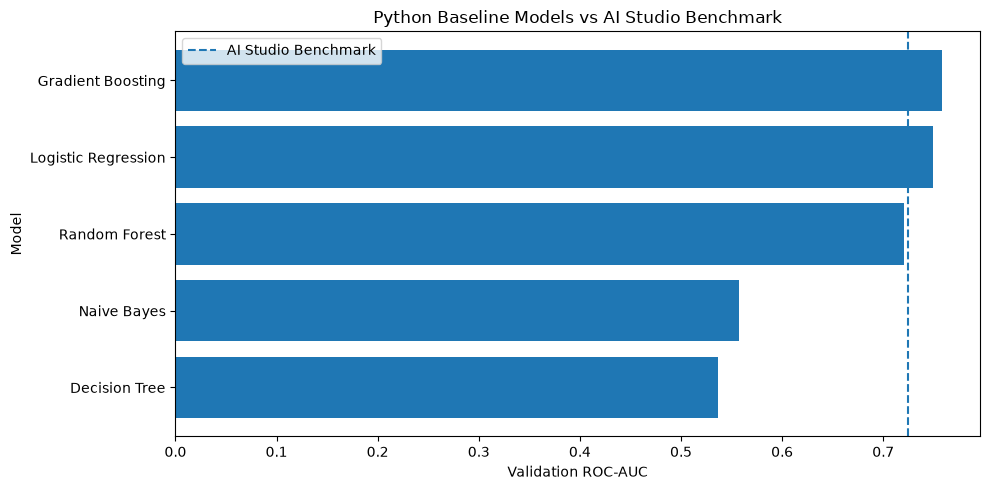

In [80]:
plt.figure(figsize=(10, 5))

plt.barh(python_baseline_results["Model"], python_baseline_results["ROC-AUC"])

plt.axvline(x=AI_STUDIO_BENCHMARK_VALIDATION_AUC, linestyle="--", label="AI Studio Benchmark")

plt.xlabel("Validation ROC-AUC")
plt.ylabel("Model")
plt.title("Python Baseline Models vs AI Studio Benchmark")
plt.legend()

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "python_baseline_roc_auc_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

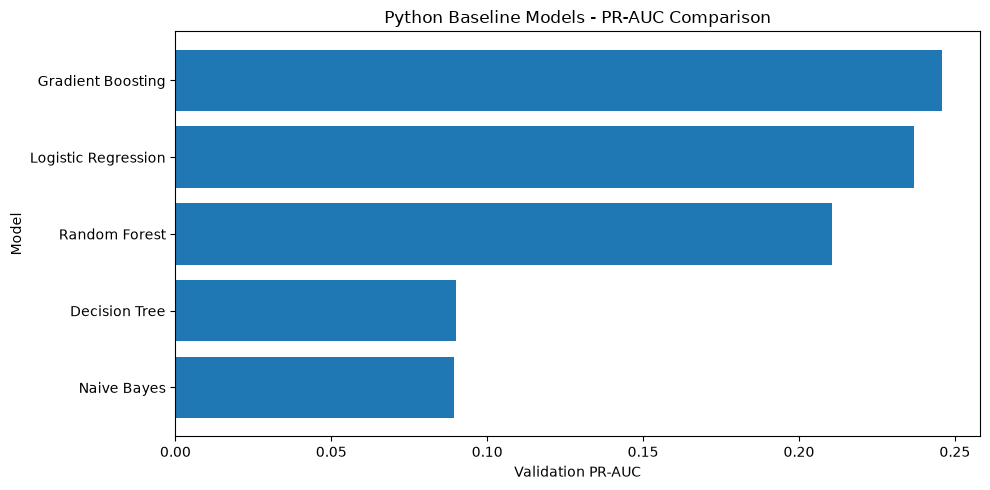

In [81]:
python_baseline_results_pr = python_baseline_results.sort_values("PR-AUC", ascending=False)

plt.figure(figsize=(10, 5))

plt.barh(python_baseline_results_pr["Model"], python_baseline_results_pr["PR-AUC"])

plt.xlabel("Validation PR-AUC")
plt.ylabel("Model")
plt.title("Python Baseline Models - PR-AUC Comparison")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "python_baseline_pr_auc_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

5.11 Comparison Against AI Studio Benchmark

The formal AI Studio benchmark established in Section 4 was a Gradient Boosted Trees model with a fixed-validation ROC-AUC of **0.724**.

Two standard Python baseline models exceeded this benchmark without hyperparameter optimisation:

- Gradient Boosting: **0.7578**

- Logistic Regression: **0.7492**

Gradient Boosting improved on the AI Studio benchmark by approximately **0.0338 ROC-AUC points**, while Logistic Regression improved it by approximately **0.0252 points**.

Random Forest achieved **0.7201**, finishing slightly below the AI Studio benchmark by approximately **0.0039 points**.

Naive Bayes and Decision Tree performed substantially below the benchmark.

Importantly, these improvements were obtained before introducing advanced hyperparameter tuning, class-imbalance strategies or threshold optimisation.

In [65]:
python_baseline_results["AI Studio Benchmark"] = AI_STUDIO_BENCHMARK_VALIDATION_AUC
python_baseline_results["ROC-AUC Difference vs AI Studio"] = (python_baseline_results["ROC-AUC"] - python_baseline_results["AI Studio Benchmark"])
python_baseline_results["Beats AI Studio Benchmark"] = (python_baseline_results["ROC-AUC"] > AI_STUDIO_BENCHMARK_VALIDATION_AUC)

In [66]:
python_baseline_results[
    [
        "Model",
        "ROC-AUC",
        "AI Studio Benchmark",
        "ROC-AUC Difference vs AI Studio",
        "Beats AI Studio Benchmark"
    ]
]

,Model,ROC-AUC,AI Studio Benchmark,ROC-AUC Difference vs AI Studio,Beats AI Studio Benchmark
0,Gradient Boosting,0.757800,0.724,0.033800,True
1,Logistic Regression,0.749211,0.724,0.025211,True
2,Random Forest,0.720081,0.724,-0.003919,False
3,Naive Bayes,0.557548,0.724,-0.166452,False
4,Decision Tree,0.536317,0.724,-0.187683,False


5.12 Baseline Candidate Selection

In [67]:
best_python_baseline_result = python_baseline_results.iloc[0]
BEST_PYTHON_BASELINE_MODEL = best_python_baseline_result["Model"]
BEST_PYTHON_BASELINE_VALIDATION_AUC = float(best_python_baseline_result["ROC-AUC"])

In [68]:
print("Best Python Baseline Model:", BEST_PYTHON_BASELINE_MODEL)
print("Validation ROC-AUC:", round(BEST_PYTHON_BASELINE_VALIDATION_AUC, 4))
print("AI Studio Benchmark ROC-AUC:", round(AI_STUDIO_BENCHMARK_VALIDATION_AUC, 4))
print("Difference:", round(BEST_PYTHON_BASELINE_VALIDATION_AUC - AI_STUDIO_BENCHMARK_VALIDATION_AUC, 4))

Best Python Baseline Model: Gradient Boosting
Validation ROC-AUC: 0.7578
AI Studio Benchmark ROC-AUC: 0.724
Difference: 0.0338


Gradient Boosting was selected as the strongest Python baseline model because it achieved the highest fixed-validation ROC-AUC (**0.7578**).

The model also achieved the highest PR-AUC (**0.2458**), providing additional evidence that its improvement was not limited to ROC-AUC alone.

Compared with the AI Studio benchmark ROC-AUC of **0.724**, the Python Gradient Boosting baseline achieved an absolute improvement of **0.0338**.

For this reason, Gradient Boosting becomes the primary baseline candidate to carry forward into the advanced modelling stage.

Logistic Regression is also retained as an important secondary reference because it achieved a strong ROC-AUC of **0.7492** while offering a considerably simpler and more interpretable modelling structure.

In [69]:
baseline_validation_predictions = {
    "Logistic Regression": lr_validation_prediction,
    "Naive Bayes": nb_validation_prediction,
    "Decision Tree": dt_validation_prediction,
    "Random Forest": rf_validation_prediction,
    "Gradient Boosting": gb_validation_prediction
}
BEST_MODEL_VALIDATION_PREDICTION = baseline_validation_predictions[BEST_PYTHON_BASELINE_MODEL]

In [70]:
best_baseline_confusion_matrix = confusion_matrix(
    y_validation,
    BEST_MODEL_VALIDATION_PREDICTION,
    labels=[0, 1]
)
best_baseline_confusion_df = pd.DataFrame(
    best_baseline_confusion_matrix,
    index=["Actual TARGET 0", "Actual TARGET 1"],
    columns=["Predicted TARGET 0", "Predicted TARGET 1"]
)
best_baseline_confusion_df

,Predicted TARGET 0,Predicted TARGET 1
Actual TARGET 0,42368,35
Actual TARGET 1,3666,58


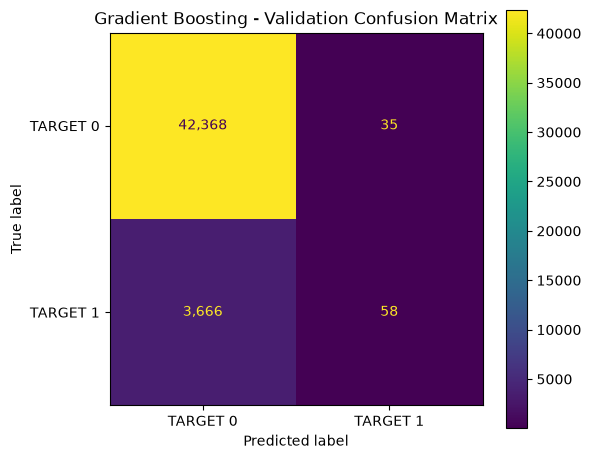

In [82]:
fig, ax = plt.subplots(figsize=(6, 5))

confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=best_baseline_confusion_matrix,
    display_labels=["TARGET 0", "TARGET 1"]
)
confusion_display.plot(
    ax=ax,
    values_format=","
)
plt.title(f"{BEST_PYTHON_BASELINE_MODEL} - Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "best_python_baseline_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

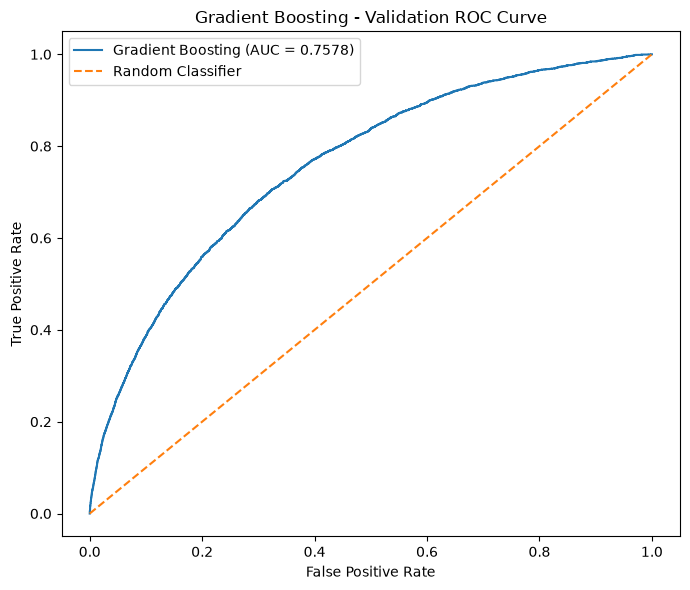

In [83]:
fpr_gb, tpr_gb, _ = roc_curve(y_validation, gb_validation_probability)
plt.figure(figsize=(7, 6))

plt.plot(
    fpr_gb,
    tpr_gb,
    label=(f"Gradient Boosting (AUC = {gb_baseline_results['ROC-AUC']:.4f})")
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gradient Boosting - Validation ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "best_python_baseline_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

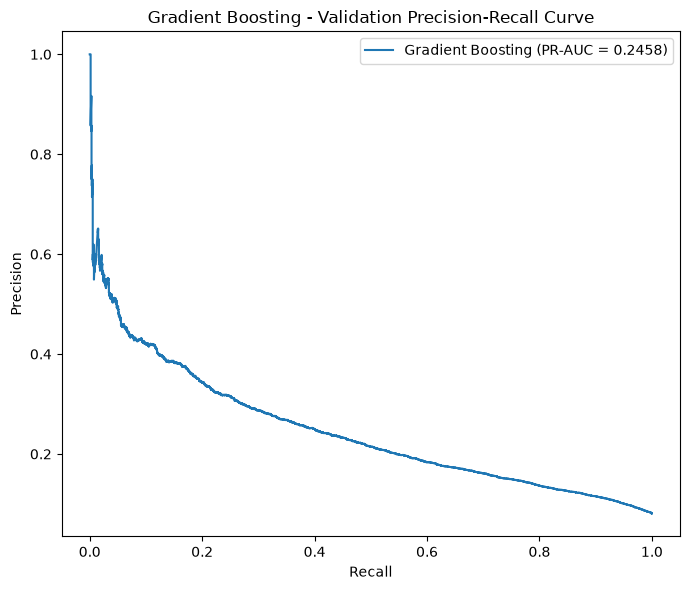

In [84]:
precision_gb, recall_gb, _ = precision_recall_curve(y_validation, gb_validation_probability)

plt.figure(figsize=(7, 6))
plt.plot(
    recall_gb,
    precision_gb,
    label=(f"Gradient Boosting (PR-AUC = {gb_baseline_results['PR-AUC']:.4f})")
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Gradient Boosting - Validation Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "best_python_baseline_pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()

5.13 Export Baseline Results

In [74]:
python_baseline_results.to_csv(PYTHON_RESULTS_DIR / "python_baseline_results.csv", index=False)

In [75]:
python_baseline_summary = pd.DataFrame({
    "Measure": [
        "Best Python Baseline Model",
        "Best Python Validation ROC-AUC",
        "AI Studio Benchmark Model",
        "AI Studio Validation ROC-AUC",
        "ROC-AUC Difference"
    ],
    "Value": [
        BEST_PYTHON_BASELINE_MODEL,
        BEST_PYTHON_BASELINE_VALIDATION_AUC,
        AI_STUDIO_BENCHMARK_MODEL,
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        (BEST_PYTHON_BASELINE_VALIDATION_AUC - AI_STUDIO_BENCHMARK_VALIDATION_AUC)
    ]
})

python_baseline_summary

,Measure,Value
0,Best Python Baseline Model,Gradient Boosting
1,Best Python Validation ROC-AUC,0.7578
2,AI Studio Benchmark Model,Gradient Boosted Trees
3,AI Studio Validation ROC-AUC,0.724
4,ROC-AUC Difference,0.0338


In [76]:
python_baseline_summary.to_csv(PYTHON_RESULTS_DIR / "python_baseline_summary.csv", index=False)

In [77]:
best_baseline_confusion_df.to_csv(PYTHON_RESULTS_DIR / "best_python_baseline_confusion_matrix.csv")

The fitted Python baseline models are saved to the project model repository to preserve the exact trained estimators used during the baseline comparison.

Saving these artefacts supports reproducibility and allows later notebooks to reference the fitted baseline models without redefining their configurations.

In [78]:
baseline_models = {
    "logistic_regression": logistic_regression_baseline,
    "naive_bayes": naive_bayes_baseline,
    "decision_tree": decision_tree_baseline,
    "random_forest": random_forest_baseline,
    "gradient_boosting": gradient_boosting_baseline
}

for model_name, model in baseline_models.items():
    model_path = MODEL_DIR / f"{model_name}_baseline.joblib"
    joblib.dump(model, model_path)

print("Baseline models saved successfully.")

Baseline models saved successfully.


In [79]:
best_python_baseline_model = baseline_models["gradient_boosting"]
BEST_BASELINE_MODEL_PATH = (MODEL_DIR / "best_python_baseline_model.joblib")
joblib.dump(best_python_baseline_model, BEST_BASELINE_MODEL_PATH)
print("Best baseline model saved at:", BEST_BASELINE_MODEL_PATH)

Best baseline model saved at: ../models/baseline/best_python_baseline_model.joblib


5.14 Conclusions

Five standard Python classification models were evaluated using the fixed train and validation partitions established during the notebook of Data Preparation.

Gradient Boosting achieved the strongest overall baseline performance, with a validation ROC-AUC of **0.7578** and PR-AUC of **0.2458**.

Logistic Regression also performed strongly, achieving a ROC-AUC of **0.7492**, while Random Forest achieved **0.7201**. Naive Bayes and Decision Tree showed substantially weaker discriminatory performance.

The strongest Python baseline therefore exceeded the formal AI Studio benchmark of **0.724** by approximately **0.0338 ROC-AUC points**.

This improvement was achieved using a standard Gradient Boosting implementation without hyperparameter tuning, resampling or threshold optimisation.

However, analysis of the default classification threshold revealed very low Recall for the positive class. The Gradient Boosting model identified only 58 of the 3,724 positive validation cases at its default classification threshold.

This demonstrates that model discrimination and operational classification behaviour must be treated separately. The model can rank applicant risk effectively while still requiring an alternative decision threshold to satisfy the business objective of identifying applicants at risk of payment difficulties.

The Python baseline stage therefore establishes two important findings:

1. A standard Python Gradient Boosting model already improves upon the AI Studio benchmark in terms of ROC-AUC.

2. Further work is required to improve minority-class decision performance and investigate the trade-off between Recall, Precision and business risk.

Gradient Boosting is therefore carried forward as the primary baseline candidate for advanced modelling, while Logistic Regression remains a strong interpretable reference model.

The next modelling stage will investigate whether advanced algorithms, hyperparameter optimisation and appropriate imbalance-aware strategies can further improve validation performance beyond the current Python baseline ROC-AUC of **0.7578**.